# People on Banknotes

Whose faces appear on banknotes?

The file `people-on-banknotes.csv` contains data about individuals featured on banknotes from 38 countries. This dataset spans all 22 subregions and sub-subregions of the world, as defined by the United Nations Statistics Division's geoscheme.

It profiles 241 people, detailing their occupations and the year they first appeared on a banknote. Additionally, it includes their year of death — or `NaN` if they were still alive when the dataset was compiled.

Most banknotes were issued after the featured individual’s death. The column `first_death_diff` calculates the difference between the year of their first appearance on a banknote and their year of death (or remains `NaN` if the person was still living at the time of curation).




In [1]:
# FOR GOOGLE COLAB ONLY.
# Uncomment and run the code below. A dialog will appear to upload files.
# Upload 'people-on-banknotes.csv'.

# from google.colab import files
# uploaded = files.upload()

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('people-on-banknotes.csv')
df

,country,currency,name,gender,occupation,value,first_appearance,death,first_death_diff,currency_code
0,Argentina,Argentine Peso,Eva Perón,F,Activist,100,2012,1952,60.0,ARS
1,Argentina,Argentine Peso,Julio Argentino Roca,M,Head of Gov't,100,1988,1914,74.0,ARS
2,Argentina,Argentine Peso,Domingo Faustino Sarmiento,M,Head of Gov't,50,1999,1888,111.0,ARS
3,Argentina,Argentine Peso,Juan Manuel de Rosas,M,Politician,20,1992,1877,115.0,ARS
4,Argentina,Argentine Peso,Manuel Belgrano,M,Founder,10,1970,1820,150.0,ARS
...,...,...,...,...,...,...,...,...,...,...
274,Venezuela,Venezuelan Bolivar,Francisco de Miranda,M,Military,200,1968,1816,152.0,VES
275,Venezuela,Venezuelan Bolivar,Simón Rodrigues,M,Educator,20,2007,1854,153.0,VES
276,Venezuela,Venezuelan Bolivar,Ezequiel Zamora,M,Military,100,2018,1860,158.0,VES
277,Venezuela,Venezuelan Bolivar,Rafael Urdaneta,M,Head of Gov't,10,2018,1845,173.0,VES


### Quick cleaning

The same person can appear on multiple banknotes. Below we drop the `value` column and remove duplicate people.

In [3]:
df = df.drop(columns=['value'])
df = df.drop_duplicates(subset="name")
df

,country,currency,name,gender,occupation,first_appearance,death,first_death_diff,currency_code
0,Argentina,Argentine Peso,Eva Perón,F,Activist,2012,1952,60.0,ARS
1,Argentina,Argentine Peso,Julio Argentino Roca,M,Head of Gov't,1988,1914,74.0,ARS
2,Argentina,Argentine Peso,Domingo Faustino Sarmiento,M,Head of Gov't,1999,1888,111.0,ARS
3,Argentina,Argentine Peso,Juan Manuel de Rosas,M,Politician,1992,1877,115.0,ARS
4,Argentina,Argentine Peso,Manuel Belgrano,M,Founder,1970,1820,150.0,ARS
...,...,...,...,...,...,...,...,...,...
274,Venezuela,Venezuelan Bolivar,Francisco de Miranda,M,Military,1968,1816,152.0,VES
275,Venezuela,Venezuelan Bolivar,Simón Rodrigues,M,Educator,2007,1854,153.0,VES
276,Venezuela,Venezuelan Bolivar,Ezequiel Zamora,M,Military,2018,1860,158.0,VES
277,Venezuela,Venezuelan Bolivar,Rafael Urdaneta,M,Head of Gov't,2018,1845,173.0,VES


### Project Ideas

- What proportion of individuals featured are male versus female?
	- Hint: Use `value_counts(normalize=True)` to calculate percentages.

- Are writers or politicians more commonly depicted?

- What percentage of featured individuals are musicians?

- What percentage of banknotes were issued before the person’s death?
	- Hint: Look for negative values or NaN in `first_death_diff`.

- Who is the oldest historical figure in the dataset?

- Which countries feature the oldest historical figures on their banknotes?
	- Hint: Group by country and aggregate the year of death using the median. Sort the results.

- What percentage of individuals died at least 100 years before appearing on a banknote?

- Which individuals appeared on a banknote just one year after their death?


# 1. Gender

In [4]:
df['gender'].value_counts(normalize=True)

gender
M    0.780083
F    0.219917
Name: proportion, dtype: float64

# 2. Writers vs. Politicians

In [5]:
df['occupation'].value_counts(normalize=True).reset_index().query('occupation == "Politician" or occupation == "Musician"')


,occupation,proportion
2,Politician,0.112033
8,Musician,0.049793


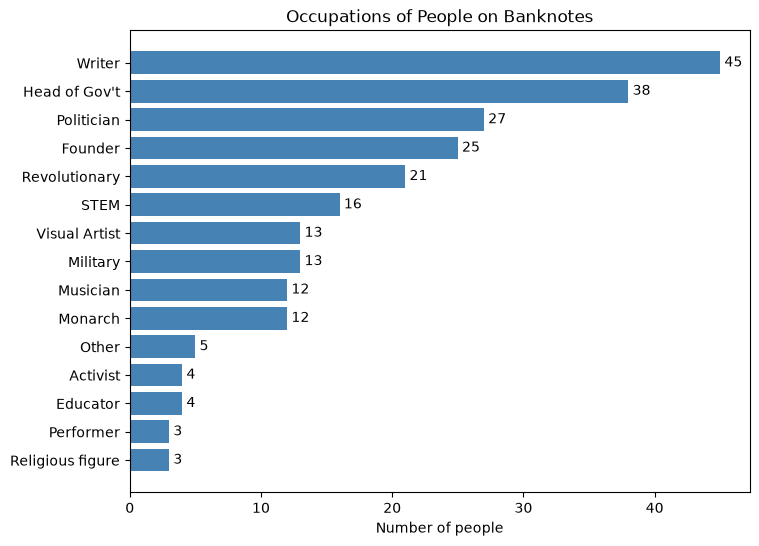

In [6]:
occupations = df['occupation'].value_counts().sort_values()

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(occupations.index, occupations.values, color='steelblue')
ax.set_title('Occupations of People on Banknotes')
ax.set_xlabel('Number of people')
ax.bar_label(ax.containers[0], padding=3)
plt.show()